<a href="https://colab.research.google.com/github/satyamchaurasia-4444/VGG16-Building-a-Brain-Tumor-Detection-Using-Deep-Learning/blob/main/MRI_data_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import random
from PIL import Image,ImageEnhance
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Flatten,Dropout,Dense
from tensorflow.keras.optimizers import Adam
from keras.optimizers import Adam
from keras.applications import VGG16
from sklearn.utils import shuffle

In [2]:
train_dir='/content/drive/MyDrive/MRI data/CNN/Training'
test_dir='/content/drive/MyDrive/MRI data/CNN/Testing'

In [3]:
train_paths=[]
train_labels=[]

for label in os.listdir(train_dir):
  for image in os.listdir(os.path.join(train_dir,label)):
    train_paths.append(os.path.join(train_dir,label,image))
    train_labels.append(label)
train_paths,train_labels=shuffle(train_paths,train_labels)

In [4]:
test_paths=[]
test_labels=[]

for label in os.listdir(test_dir):
  for image in os.listdir(os.path.join(test_dir,label)):
    test_paths.append(os.path.join(test_dir,label,image))
    test_labels.append(label)
test_paths, test_labels = shuffle(test_paths, test_labels)

In [5]:
# Data visualization

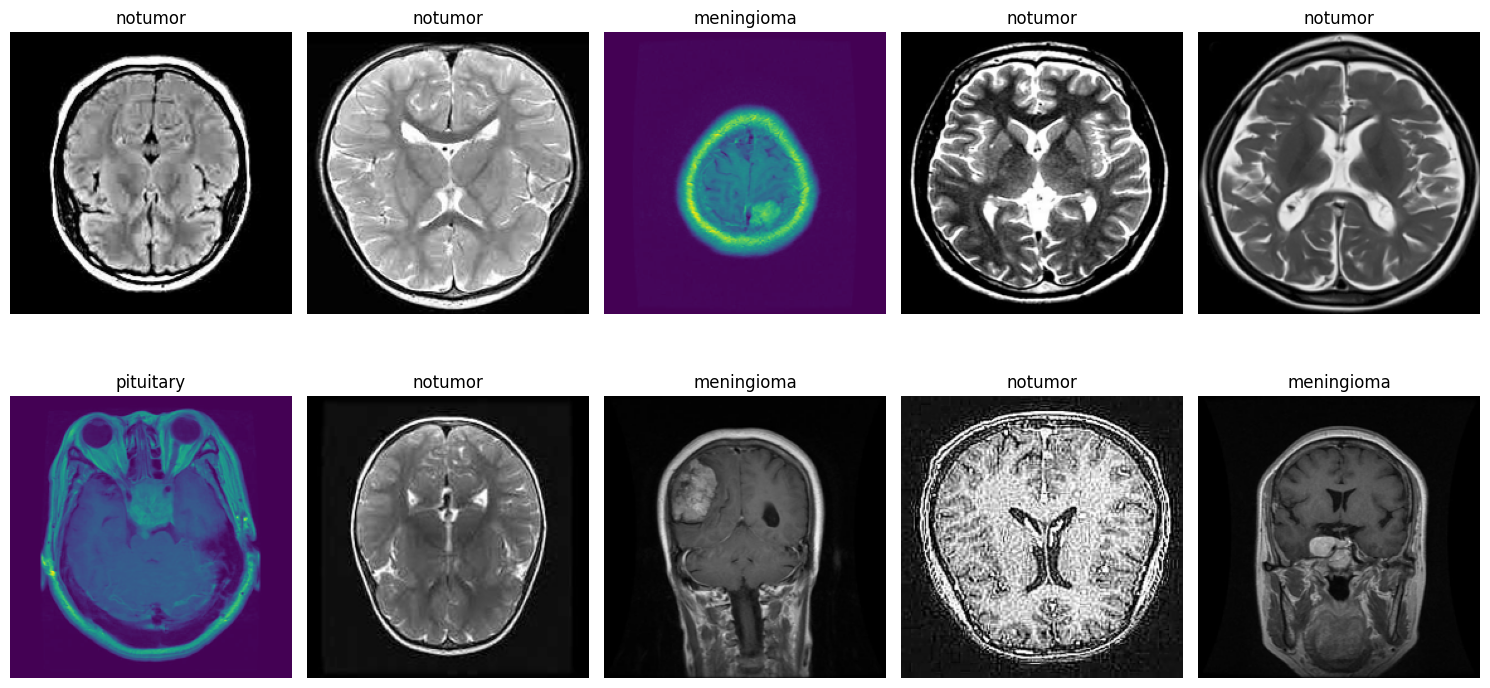

In [6]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import os

random_indices=random.sample(range(len(train_paths)),10)

fig,axes=plt.subplots(2,5,figsize=(15,8))
axes=axes.ravel()

# Before ravel()
axes.shape
# (2, 5)

# After ravel()
axes.shape
# (10,)

for i,idx in enumerate(random_indices):
  img_path=train_paths[idx]
  img=Image.open(img_path)
  img=img.resize((224,224))


  axes[i].imshow(img)
  axes[i].axis('off')
  axes[i].set_title(train_labels[idx])
plt.tight_layout()
plt.show()


In [7]:
# Image preprocessing

# Image Augmentation

def augment_image(image):
  image=Image.fromarray(np.uint8(image))
  image=ImageEnhance.Brightness(image).enhance(random.uniform(0.8,1.2))
  image=ImageEnhance.Contrast(image).enhance(random.uniform(0.8,1.2))
  image=np.array(image)/255.0
  return image


# load image and apply augmentation
def open_images(paths):
  images=[]
  for path in paths:
    image=load_img(path,target_size=(IMAGE_SIZE,IMAGE_SIZE))
    image=augment_image(image)
    images.append(image)
  return np.array(images)


# convert label name into int,Encoding


def encode_label(labels):
    unique_labels = os.listdir(train_dir)
    encoded = []

    for label in labels:
        number = unique_labels.index(label)
        encoded.append(number)

    return np.array(encoded)

    # Data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)  # Open and augment images
            batch_labels = labels[i:i + batch_size]
            batch_labels = encode_label(batch_labels)  # Encode labels
            yield batch_images, batch_labels  # Yield the batch

In [8]:
# Model Architecture

IMAGE_SIZE=128

base_model=VGG16(input_shape=(IMAGE_SIZE,IMAGE_SIZE,3),include_top=False,weights='imagenet')

for layer in base_model.layers:
  layer.trainable=False

base_model.layers[-2].trainable=True
base_model.layers[-3].trainable=True
base_model.layers[-4].trainable=True


model=Sequential()
model.add(Input(shape=(IMAGE_SIZE,IMAGE_SIZE,3)))
model.add(base_model)
model.add(Flatten())
model.add(Dropout(0.3))
model.add(Dense(128,activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(len(os.listdir(train_dir)),activation='softmax'))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [9]:

model.compile(optimizer=Adam(learning_rate=0.0001),loss='sparse_categorical_crossentropy',metrics=['sparse_categorical_accuracy'])


In [10]:
batch_size = 20
steps = int(len(train_paths) / batch_size)  # Steps per epoch
epochs = 5

In [11]:
history=model.fit(datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),epochs=epochs, steps_per_epoch=steps)

Epoch 1/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 2483s 9s/step - loss: 0.4910 - sparse_categorical_accuracy: 0.8121
Epoch 2/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - loss: 0.2532 - sparse_categorical_accuracy: 0.9031
Epoch 3/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 29s 103ms/step - loss: 0.1806 - sparse_categorical_accuracy: 0.9346
Epoch 4/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 29s 105ms/step - loss: 0.1328 - sparse_categorical_accuracy: 0.9467
Epoch 5/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 29s 104ms/step - loss: 0.0911 - sparse_categorical_accuracy: 0.9677


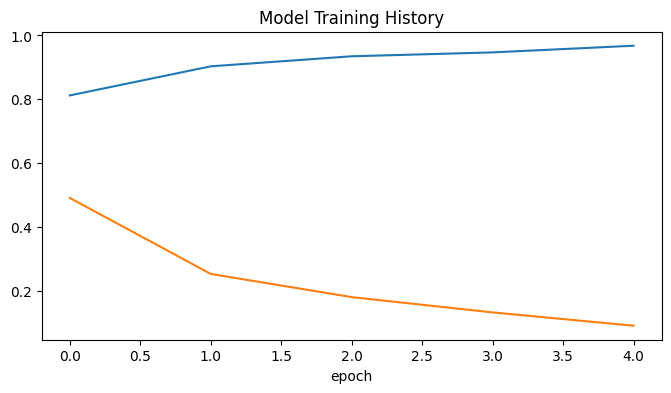

In [12]:
plt.figure(figsize=(8,4))
plt.plot(history.history['sparse_categorical_accuracy'])
plt.plot(history.history['loss'])
plt.title('Model Training History')
plt.xlabel('epoch')
plt.show()

In [14]:
from sklearn.metrics import classification_report
import seaborn as sns
from tensorflow.keras.models import load_model
import numpy as np


test_images=open_images(test_paths)
test_labels_encoded=encode_label(test_labels)
test_prediction=model.predict(test_images)

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step


In [15]:
test_prediction

array([[3.1438500e-01, 3.1254667e-01, 3.4139267e-01, 3.1675600e-02],
       [9.8434991e-01, 1.4183642e-02, 6.6832575e-04, 7.9824892e-04],
       [9.9997234e-01, 2.7257383e-05, 1.5331297e-07, 2.6527951e-07],
       ...,
       [1.0000000e+00, 1.0351561e-10, 3.5035681e-12, 2.9241224e-11],
       [3.8026804e-01, 3.7149313e-01, 1.6871819e-04, 2.4807011e-01],
       [3.8330421e-05, 3.1459448e-04, 3.6602100e-06, 9.9964345e-01]],
      dtype=float32)

In [17]:
np.argmax(test_prediction,axis=1)

array([2, 0, 0, ..., 0, 0, 3])

In [18]:
print(classification_report(test_labels_encoded, np.argmax(test_prediction, axis=1)))

              precision    recall  f1-score   support

           0       0.79      0.99      0.88       400
           1       0.94      0.73      0.82       400
           2       0.91      0.75      0.83       400
           3       0.88      1.00      0.93       400

    accuracy                           0.87      1600
   macro avg       0.88      0.87      0.87      1600
weighted avg       0.88      0.87      0.87      1600



In [19]:
model.save('model.h5')